# Visualisasi — Deret Waktu (pola, musiman, ramalan)
**Kapan dipakai:** "bagaimana pola seri ini? naik/turun? berulang tiap jam/hari/bulan? seberapa
jauh ramalan meleset?"

**Isi:** line + rolling, seasonal plot, box per jam/hari, heatmap jam x hari dan kalender,
dekomposisi STL, ACF/PACF, aktual vs ramalan + interval, plotly dengan range slider.
Semua gambar disimpan di folder notebook.

**Data demo:** NYC taxi (30 menit), Flights (bulanan, musiman kuat).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/timeseries"   # GANTI saat lomba
TAXI_CSV = f"{DATA_FOLDER}/anomaly/nyc_taxi.csv"
FLIGHTS_CSV = f"{DATA_FOLDER}/forecasting/flights_monthly.csv"

TIME_COL = "timestamp"
VALUE_COL = "value"
ANOMALY_COL = "is_anomaly"
MONTHLY_PERIOD = 12    # musiman tahunan pada data bulanan
FORECAST_STEPS = 24    # bulan ke depan yang diramal
DAY_NAMES = ["Sen", "Sel", "Rab", "Kam", "Jum", "Sab", "Min"]
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

## Gaya grafik (sama di semua notebook visualisasi)
Font besar supaya terbaca di slide, palet tetap, garis tepi atas/kanan dimatikan.

In [3]:
PALETTE = ["#2E6FB7", "#F28E2B", "#3BA272", "#D1495B", "#7B5EA7", "#9AA0A6"]
BLUE, ORANGE, GREEN, RED, PURPLE, GREY = PALETTE
plt.rcParams.update({
    "figure.figsize": (8, 5), "figure.dpi": 100, "savefig.dpi": 200,
    "font.size": 14, "axes.titlesize": 18, "axes.titleweight": "bold", "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})
sns.set_palette(PALETTE)

## Baca data

In [4]:
taxi = pd.read_csv(TAXI_CSV, index_col=TIME_COL, parse_dates=True)
flights_table = pd.read_csv(FLIGHTS_CSV, index_col="date", parse_dates=True)
flights = flights_table["value"].asfreq("MS")
daily = taxi[VALUE_COL].resample("D").mean()
print(taxi.shape, flights.shape, daily.index.min(), daily.index.max())
taxi.head(3)

(10320, 2) (144,) 2014-07-01 00:00:00 2015-01-31 00:00:00


,value,is_anomaly
timestamp,,
2014-07-01 00:00:00,10844,0
2014-07-01 00:30:00,8127,0
2014-07-01 01:00:00,6210,0


## 1. Line plot + rata-rata bergulir (rolling)
**Kapan dipakai:** pandangan pertama pada seri, melihat tren dan lonjakan.
**Cara baca:** garis tipis = data harian, garis tebal = rata-rata 7 hari (tren tanpa riak
mingguan), titik merah = hari anomali yang diberi label di data.

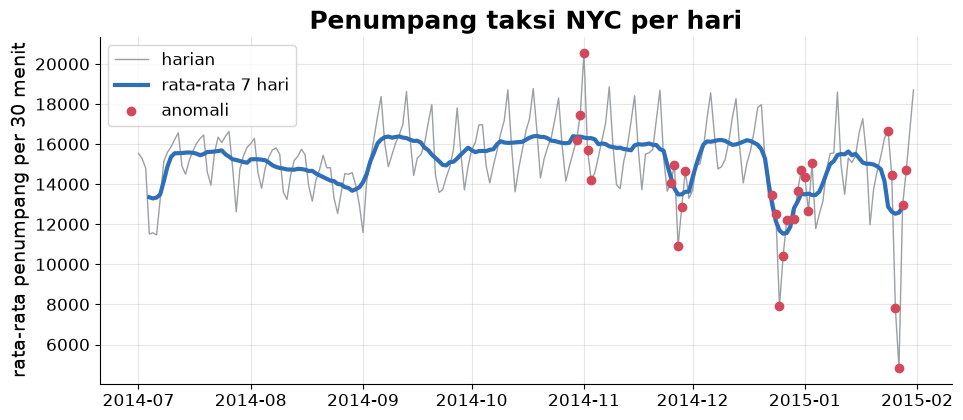

In [5]:
anomaly_values = taxi.loc[taxi[ANOMALY_COL] == 1, VALUE_COL]
anomaly_days = anomaly_values.resample("D").mean()
anomaly_days = anomaly_days.dropna()
rolling_mean = daily.rolling(7, center=True).mean()
plt.figure(figsize=(11, 4.5))
plt.plot(daily, color=GREY, linewidth=1, label="harian")
plt.plot(rolling_mean, color=BLUE, linewidth=3, label="rata-rata 7 hari")
plt.scatter(anomaly_days.index, daily[anomaly_days.index], color=RED, zorder=3, label="anomali")
plt.title("Penumpang taksi NYC per hari")
plt.ylabel("rata-rata penumpang per 30 menit")
plt.legend()
# Alternatif rata-rata eksponensial: daily.ewm(span=7).mean()
plt.savefig("waktu_line_rolling.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Seasonal plot (satu garis per tahun)
**Kapan dipakai:** data bulanan/mingguan dengan pola yang berulang tiap tahun.
**Cara baca:** sumbu x = bulan, satu garis per tahun. Garis sejajar = musiman stabil. Garis
makin tinggi dari tahun ke tahun = ada tren naik.

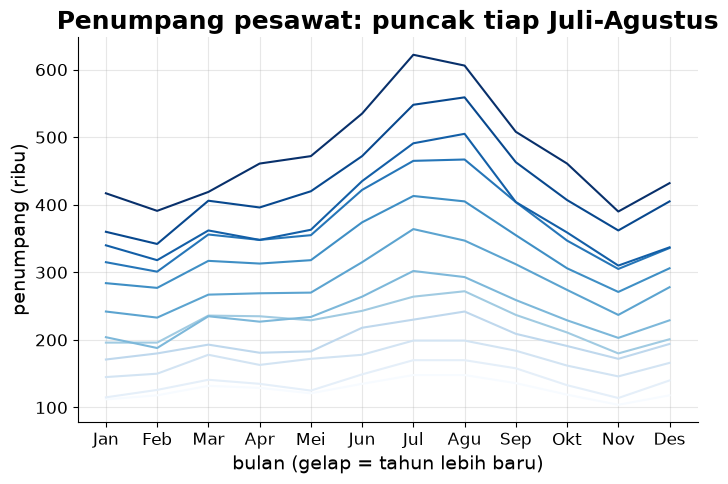

In [6]:
seasonal_table = pd.DataFrame()
seasonal_table["tahun"] = flights.index.year
seasonal_table["bulan"] = flights.index.month
seasonal_table["nilai"] = flights.to_numpy()
sns.lineplot(data=seasonal_table, x="bulan", y="nilai", hue="tahun", palette="Blues",
             legend=False)
plt.xticks(range(1, 13), MONTH_NAMES)
plt.title("Penumpang pesawat: puncak tiap Juli-Agustus")
plt.xlabel("bulan (gelap = tahun lebih baru)")
plt.ylabel("penumpang (ribu)")
plt.savefig("waktu_seasonal_plot.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Box plot per jam dan per hari
**Kapan dipakai:** menentukan fitur kalender mana yang berguna (jam, hari dalam minggu, bulan).
**Cara baca:** kotak yang bergeser naik-turun antar kategori = kalender itu berpengaruh.

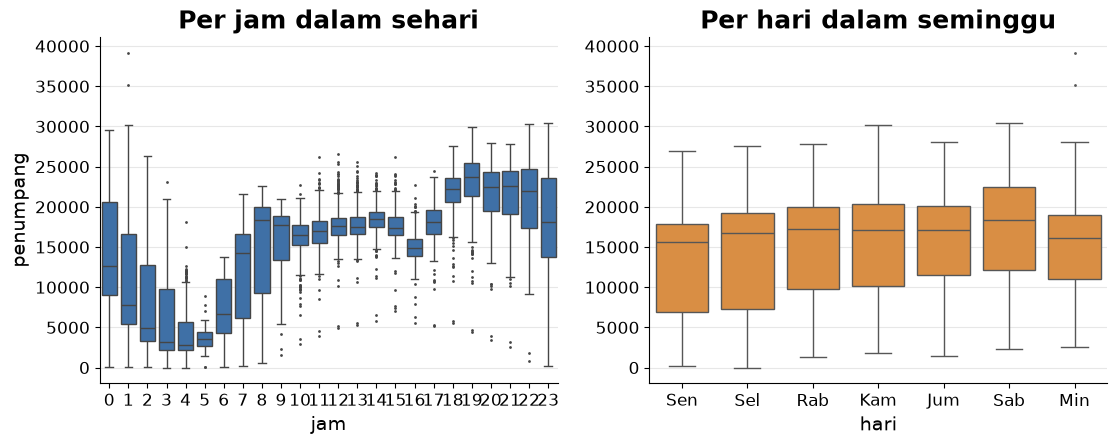

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(x=taxi.index.hour, y=taxi[VALUE_COL], color=BLUE, fliersize=1, ax=axes[0])
axes[0].set_title("Per jam dalam sehari")
axes[0].set_xlabel("jam")
axes[0].set_ylabel("penumpang")
sns.boxplot(x=taxi.index.dayofweek, y=taxi[VALUE_COL], color=ORANGE, fliersize=1, ax=axes[1])
axes[1].set_xticks(range(7), DAY_NAMES)
axes[1].set_title("Per hari dalam seminggu")
axes[1].set_xlabel("hari")
axes[1].set_ylabel("")
# Alternatif per bulan: sns.boxplot(x=flights.index.month, y=flights.values)
plt.savefig("waktu_box_jam_hari.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Heatmap jam x hari
**Kapan dipakai:** data per jam/menit, mencari jam sibuk per hari (jadwal kerja, shift, promo).
**Cara baca:** warna gelap = nilai tinggi. Pola weekday vs weekend muncul sebagai blok warna.

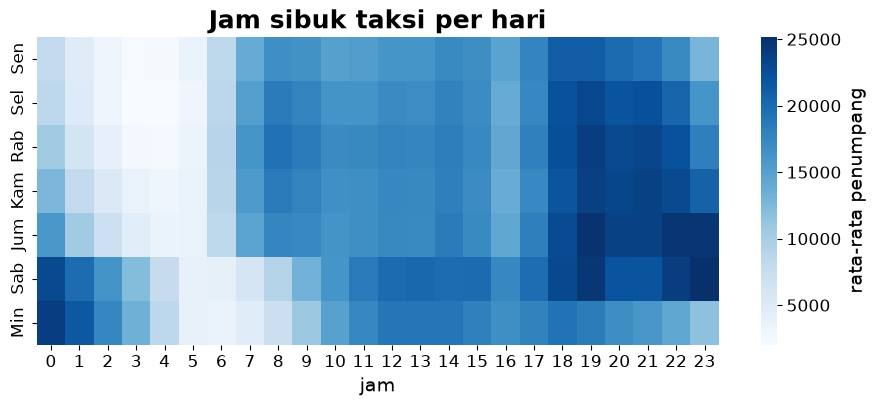

In [8]:
hour_day = taxi.pivot_table(index=taxi.index.dayofweek, columns=taxi.index.hour,
                            values=VALUE_COL, aggfunc="mean")
hour_day.index = DAY_NAMES
plt.figure(figsize=(11, 4))
sns.heatmap(hour_day, cmap="Blues", cbar_kws={"label": "rata-rata penumpang"})
plt.title("Jam sibuk taksi per hari")
plt.xlabel("jam")
plt.ylabel("")
plt.grid(False)
plt.savefig("waktu_heatmap_jam_hari.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Heatmap kalender (minggu x hari)
**Kapan dipakai:** data harian, mencari hari libur, kejadian khusus, dan pola mingguan.
**Cara baca:** satu kolom = satu minggu, satu baris = satu hari dalam minggu. Kotak yang
menyimpang dari kolom tetangganya = hari istimewa (libur, badai, acara).

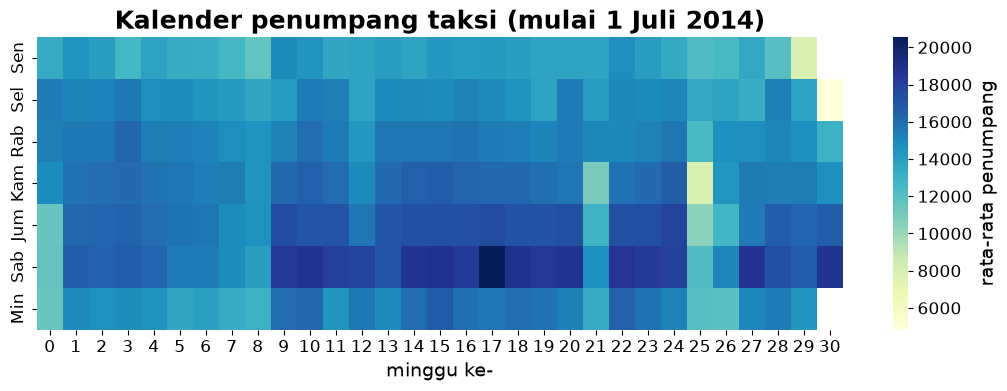

In [9]:
calendar = pd.DataFrame()
calendar["nilai"] = daily.to_numpy()
days_from_start = (daily.index - daily.index.min()).days
calendar["minggu_ke"] = days_from_start // 7
calendar["hari"] = daily.index.dayofweek
calendar_grid = calendar.pivot_table(index="hari", columns="minggu_ke", values="nilai")
calendar_grid.index = DAY_NAMES
plt.figure(figsize=(13, 3.8))
sns.heatmap(calendar_grid, cmap="YlGnBu", cbar_kws={"label": "rata-rata penumpang"})
plt.title("Kalender penumpang taksi (mulai 1 Juli 2014)")
plt.xlabel("minggu ke-")
plt.ylabel("")
plt.grid(False)
plt.savefig("waktu_heatmap_kalender.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Dekomposisi STL (tren + musiman + sisa)
**Kapan dipakai:** memisahkan komponen sebelum memilih model, memeriksa musiman dan outlier.
**Cara baca:** observed = tren + musiman + sisa. Sisa yang masih berpola berarti ada informasi
yang belum ditangkap. Dipakai log supaya amplitudo musiman yang membesar menjadi tetap.

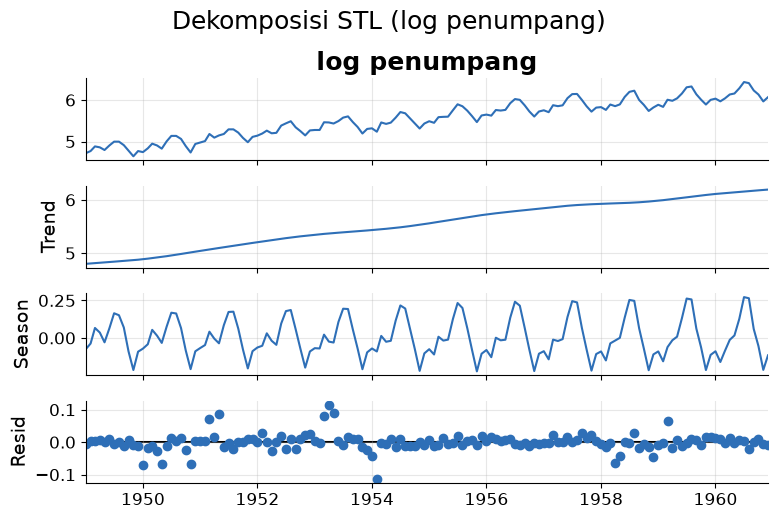

In [10]:
log_flights = np.log(flights)
log_flights = log_flights.rename("log penumpang")
stl = STL(log_flights, period=MONTHLY_PERIOD, robust=True)
decomposition = stl.fit()
decomposition.plot()
plt.suptitle("Dekomposisi STL (log penumpang)", y=1.04, fontsize=18)
plt.savefig("waktu_stl.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. ACF dan PACF
**Kapan dipakai:** memilih lag untuk fitur lag / orde ARIMA, mendeteksi musiman.
**Cara baca:** batang yang keluar dari area biru = korelasi nyata pada lag itu. Puncak di lag 12,
24 = musiman bulanan. Dipakai selisih (diff) supaya tren hilang.

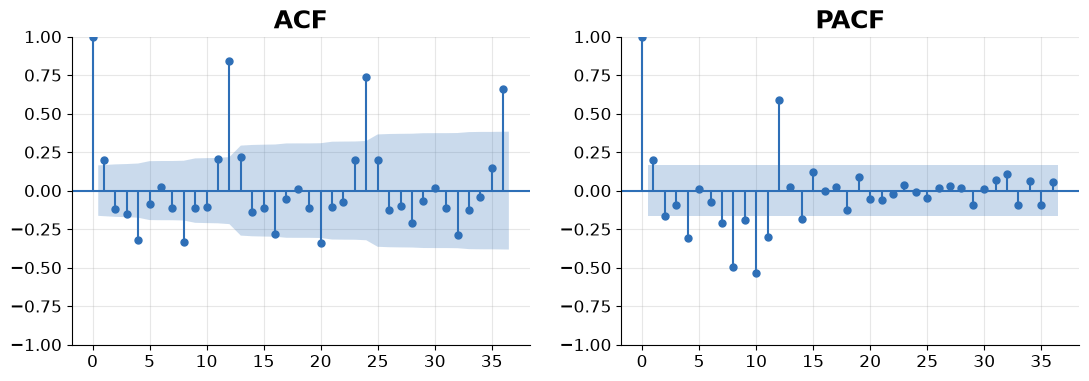

In [11]:
stationary = log_flights.diff().dropna()   # selisih antar bulan menghilangkan tren
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(stationary, lags=36, ax=axes[0])
plot_pacf(stationary, lags=36, ax=axes[1], method="ywm")
axes[0].set_title("ACF")
axes[1].set_title("PACF")
plt.savefig("waktu_acf_pacf.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Aktual vs ramalan + interval
**Kapan dipakai:** menyajikan hasil peramalan, menunjukkan ketidakpastian, bukan satu garis.
**Cara baca:** garis oranye = ramalan, pita = rentang 95%. Semakin jauh ke depan, pita melebar.
Garis biru di area ramalan = nilai asli (hanya ada saat validasi).

MAE ramalan: 39.5


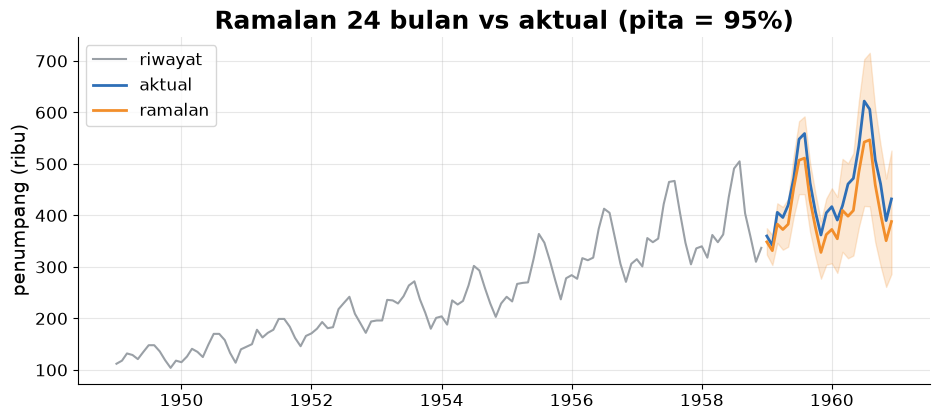

In [12]:
history = flights.iloc[:-FORECAST_STEPS]
actual = flights.iloc[-FORECAST_STEPS:]
sarimax = SARIMAX(np.log(history), order=(0, 1, 1), seasonal_order=(0, 1, 1, 12))
model = sarimax.fit(disp=False)
forecast = model.get_forecast(FORECAST_STEPS)
middle = np.exp(forecast.predicted_mean)
interval = np.exp(forecast.conf_int(alpha=0.05))
absolute_error = (actual - middle).abs()
print("MAE ramalan:", round(float(absolute_error.mean()), 1))

plt.figure(figsize=(11, 4.5))
plt.plot(history, color=GREY, label="riwayat")
plt.plot(actual, color=BLUE, linewidth=2, label="aktual")
plt.plot(middle, color=ORANGE, linewidth=2, label="ramalan")
plt.fill_between(interval.index, interval.iloc[:, 0], interval.iloc[:, 1], color=ORANGE,
                 alpha=0.2)
plt.title("Ramalan 24 bulan vs aktual (pita = 95%)")
plt.ylabel("penumpang (ribu)")
plt.legend()
plt.savefig("waktu_aktual_vs_ramalan.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Versi interaktif dengan range slider (plotly)
**Kapan dipakai:** seri panjang, ingin zoom ke periode tertentu saat diskusi/presentasi.
**Cara baca:** geser slider di bawah atau seret di grafik untuk memperbesar, hover = nilai.

In [13]:
fig = px.line(daily.rename("penumpang"), title="Penumpang taksi NYC per hari (interaktif)")
fig.update_traces(line_color=BLUE)
fig.update_xaxes(rangeslider_visible=True)
fig.write_html("waktu_interaktif.html", include_plotlyjs=True)
fig.show()